## Problem ot solve

In [13]:
with open('./3sat.dimacs', 'r', encoding='utf8') as f:
    dimacs = f.read()
print(dimacs)  # let's check the file is as promised

c example DIMACS-CNF 3-SAT
p cnf 3 5
-1 -2 -3 0
1 -2 3 0
1 2 -3 0
1 -2 -3 0
-1 2 3 0


## The Oracle

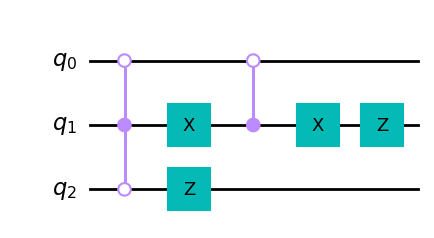

In [14]:
from qiskit.circuit.library import PhaseOracle
oracle = PhaseOracle.from_dimacs_file('./3sat.dimacs')
oracle.draw()

In [15]:
## May need to install this if error with PhaseOracle.from_dimacs_file
#pip install tweedledum

## Encode the input

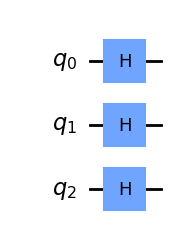

In [16]:
from qiskit import QuantumCircuit
init = QuantumCircuit(3)
init.h([0,1,2])
init.draw()

## Grover operator 
Next, we can again use Qiskit's tools to create a circuit that does steps 2 & 3 for us.

In [17]:
# steps 2 & 3 of Grover's algorithm
from qiskit.circuit.library import GroverOperator
grover_operator = GroverOperator(oracle)

And we can combine this into a circuit that performs Grover's algorithm. Here, we won't repeat steps 2 & 3 as this is a small problem and doing them once is enough.

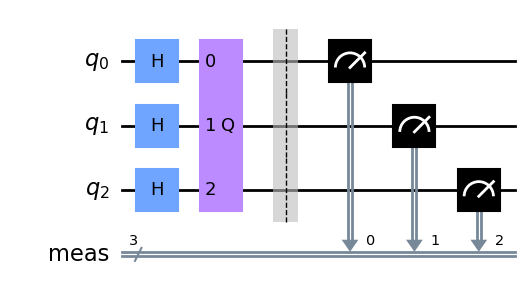

In [18]:
qc = init.compose(grover_operator)
qc.measure_all()
qc.draw()

## Run the circuit
Finally, let's run this on a simulator and see what results we get:

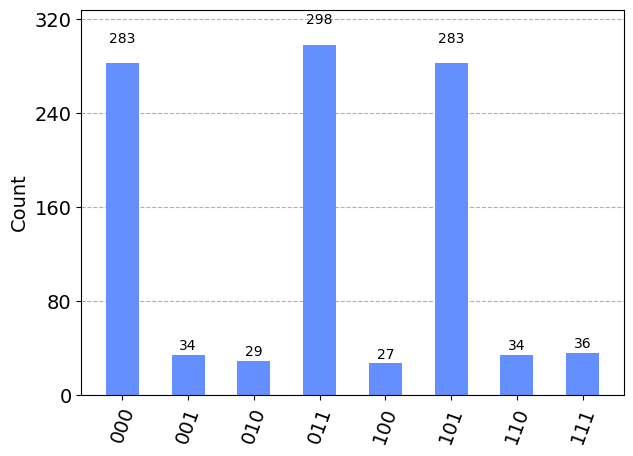

In [48]:
# Simulate the circuit
from qiskit import Aer, transpile
sim = Aer.get_backend('aer_simulator')

# Transpilation is the process of rewriting a given input circuit to match the topology of a specific quantum device, 
# and/or to optimize the circuit for execution on present day noisy quantum systems.
t_qc = transpile(qc, sim) #

# Execute
counts = sim.run(t_qc).result().get_counts()

# plot the results
from qiskit.visualization import plot_histogram
plot_histogram(counts)

We have a high probability of measuring one of the 3 solutions to the SAT problem.

# Creating an Oracle from Scratch
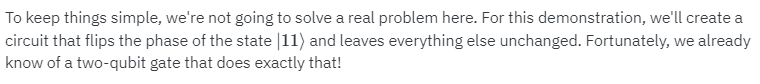

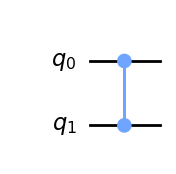

In [49]:
oracle = QuantumCircuit(2)
oracle.cz(0,1)  # invert phase of |11>
oracle.draw()

In [50]:
#Here's a short function to show the matrix representation of this circuit:

def display_unitary(qc, prefix=""):
    """Simulates a simple circuit and display its matrix representation.
    Args:
        qc (QuantumCircuit): The circuit to compile to a unitary matrix
        prefix (str): Optional LaTeX to be displayed before the matrix
    Returns:
        None (displays matrix as side effect)
    """
    from qiskit import Aer
    from qiskit.visualization import array_to_latex
    sim = Aer.get_backend('aer_simulator')
    # Next, we'll create a copy of the circuit and work on
    # that so we don't change anything as a side effect
    qc = qc.copy()
    # Tell the simulator to save the unitary matrix of this circuit
    qc.save_unitary()
    unitary = sim.run(qc).result().get_unitary()
    display(array_to_latex(unitary, prefix=prefix))

display_unitary(oracle, "U_\\text{oracle}=")

<IPython.core.display.Latex object>

### Exercice:
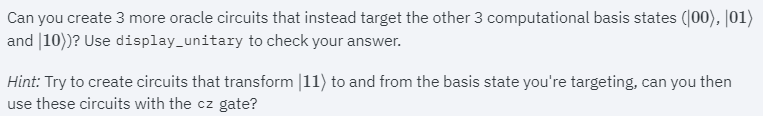
This illustrates the principle of the oracle, but...  
... a true oracle changes the phases for the solutions only!
This is the reflexion around the $|\chi\rangle$ state in Grover's algo.

### RHR: Solutions

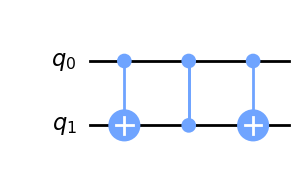

<IPython.core.display.Latex object>

In [51]:
oracle_01 = QuantumCircuit(2)
oracle_01.cx(0,1)  # from 10 to 11
oracle_01.cz(0,1)  # invert phase of |11>
oracle_01.cx(0,1)  # from 10 to 11
display(oracle_01.draw())

display_unitary(oracle_01, "U_\\text{oracle}=")

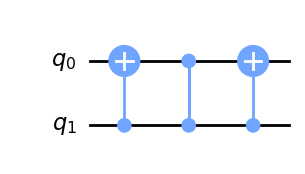

<IPython.core.display.Latex object>

In [52]:
oracle_10 = QuantumCircuit(2)
oracle_10.cx(1,0)  # from 10 to 11
oracle_10.cz(0,1)  # invert phase of |11>
oracle_10.cx(1,0)  # from 10 to 11
display(oracle_10.draw())

display_unitary(oracle_10, "U_\\text{oracle}=")

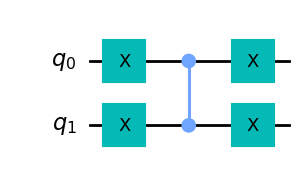

<IPython.core.display.Latex object>

In [53]:
oracle_00 = QuantumCircuit(2)
oracle_00.x([0,1])  # from 00 to 11
oracle_00.cz(0,1)  # invert phase of |11>
oracle_00.x([0,1])  # from 11 to 00
display(oracle_00.draw())

display_unitary(oracle_00, "U_\\text{oracle}=")

## Creating the diffuser from scratch
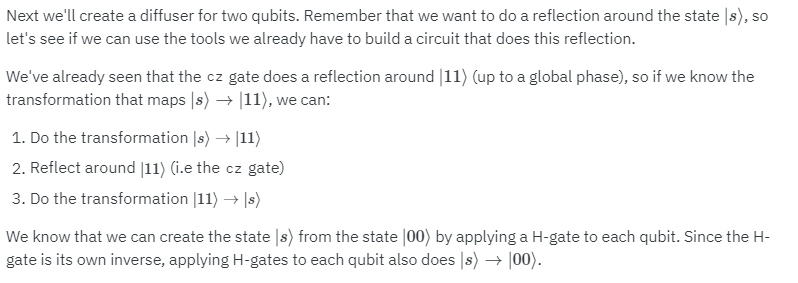

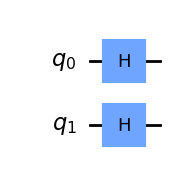

In [54]:
diffuser = QuantumCircuit(2)
diffuser.h([0, 1])
diffuser.draw()

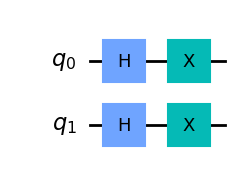

In [55]:
diffuser.x([0,1])
diffuser.draw()

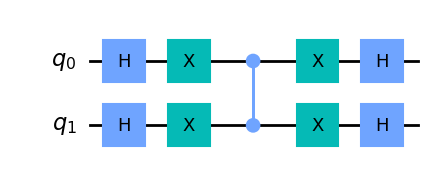

In [56]:
diffuser.cz(0,1)
diffuser.x([0,1])
diffuser.h([0,1])
diffuser.draw()

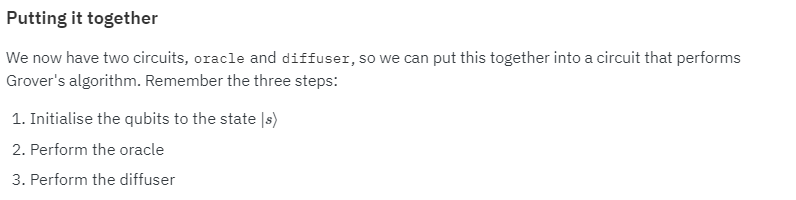

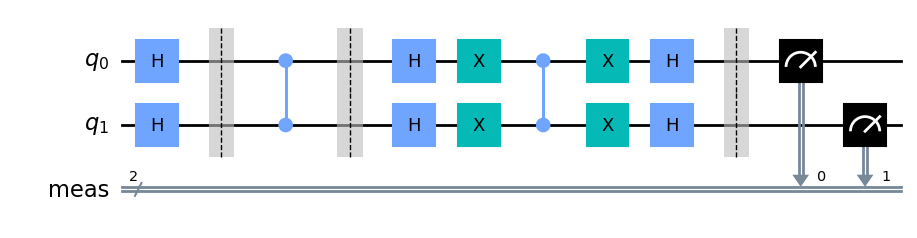

In [57]:
grover = QuantumCircuit(2)

# initialise |s>
grover.h([0,1]) 
grover.barrier()

# oracle
grover = grover.compose(oracle)
grover.barrier()

# difuser
grover = grover.compose(diffuser)

# measure
grover.measure_all()
grover.draw()

In [59]:
from qiskit import Aer
sim = Aer.get_backend('aer_simulator')
sim.run(grover).result().get_counts()

{'11': 1024}

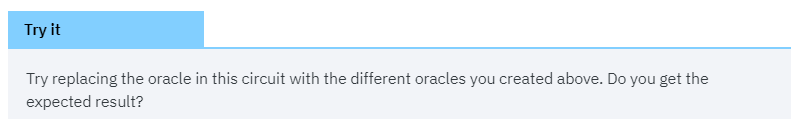

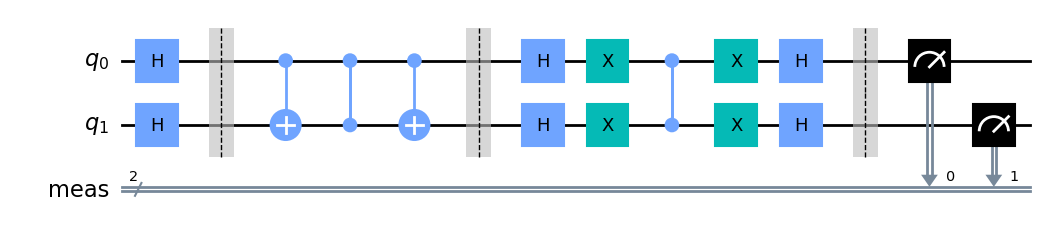

{'01': 1024}

In [63]:
## Find solution 01: use the oracle_01

grover = QuantumCircuit(2)

# initialise |s>
grover.h([0,1]) 
grover.barrier()

# oracle
grover = grover.compose(oracle_01)
grover.barrier()

# difuser
grover = grover.compose(diffuser)

# measure
grover.measure_all()
display(grover.draw())

# execute
sim.run(grover).result().get_counts()